In [1]:
import pandas as pd
print("My customer retenstion projectis starting")



My customer retenstion projectis starting


In [2]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)
df = online_retail.data.original

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (541909, 8)
Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [3]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)
df = online_retail.data.original

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (541909, 8)
Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [5]:
print("First 5 rows:")
display(df.head())

print("Dataset size:")
print(df.shape)

print("Column information:")
df.info()

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Dataset size:
(541909, 8)
Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [6]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [8]:
df_clean = df.dropna(subset=["CustomerID"]).copy()

print("Original rows:", len(df))
print("Rows after removing missing CustomerID:", len(df_clean))
print("Missing CustomerID after cleaning:",
      df_clean["CustomerID"].isnull().sum())

Original rows: 541909
Rows after removing missing CustomerID: 406829
Missing CustomerID after cleaning: 0


In [9]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 5225


In [11]:
duplicates = df_clean[df_clean.duplicated(keep=False)]

print("Total rows involved in duplicates:",
      len(duplicates))

display(duplicates.head(10))

Total rows involved in duplicates: 10062


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom


In [12]:
df_analysis = df_clean.drop_duplicates().copy()

print("Before:", len(df_clean))
print("After:", len(df_analysis))
print("Duplicates remaining:", df_analysis.duplicated().sum())

Before: 406829
After: 401604
Duplicates remaining: 0


In [13]:
print("Sample invoice numbers:")
print(df_analysis["InvoiceNo"].head(15).tolist())

print("Invoices starting with C:",
      df_analysis["InvoiceNo"].astype(str).str.startswith("C").sum())

Sample invoice numbers:
['536365', '536365', '536365', '536365', '536365', '536365', '536365', '536366', '536366', '536367', '536367', '536367', '536367', '536367', '536367']
Invoices starting with C: 8872


In [14]:
df_sales = df_analysis[
    ~df_analysis["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Rows before excluding cancellations:", len(df_analysis))
print("Rows after excluding cancellations:", len(df_sales))
print("Cancellation rows remaining:",
      df_sales["InvoiceNo"].astype(str).str.startswith("C").sum())

Rows before excluding cancellations: 401604
Rows after excluding cancellations: 392732
Cancellation rows remaining: 0


In [15]:
unique_customers = df_sales["CustomerID"].nunique()

print("Number of unique customers:", unique_customers)

Number of unique customers: 4339


In [16]:
orders_per_customer = df_sales.groupby("CustomerID")["InvoiceNo"].nunique()

repeat_customers = (orders_per_customer > 1).sum()
one_time_customers = (orders_per_customer == 1).sum()

print("Repeat customers:", repeat_customers)
print("One-time customers:", one_time_customers)
print("Total customers:", len(orders_per_customer))

Repeat customers: 2845
One-time customers: 1494
Total customers: 4339


In [18]:
repeat_rate = repeat_customers / len(orders_per_customer) * 100

print("Repeat customer rate:", round(repeat_rate, 2), "%")

Repeat customer rate: 65.57 %


InvoiceDate
2010-12-31    1708
2011-01-31    1236
2011-02-28    1202
2011-03-31    1619
2011-04-30    1384
2011-05-31    1849
2011-06-30    1707
2011-07-31    1593
2011-08-31    1544
2011-09-30    2078
2011-10-31    2263
2011-11-30    3086
2011-12-31     921
Freq: ME, Name: InvoiceNo, dtype: int64


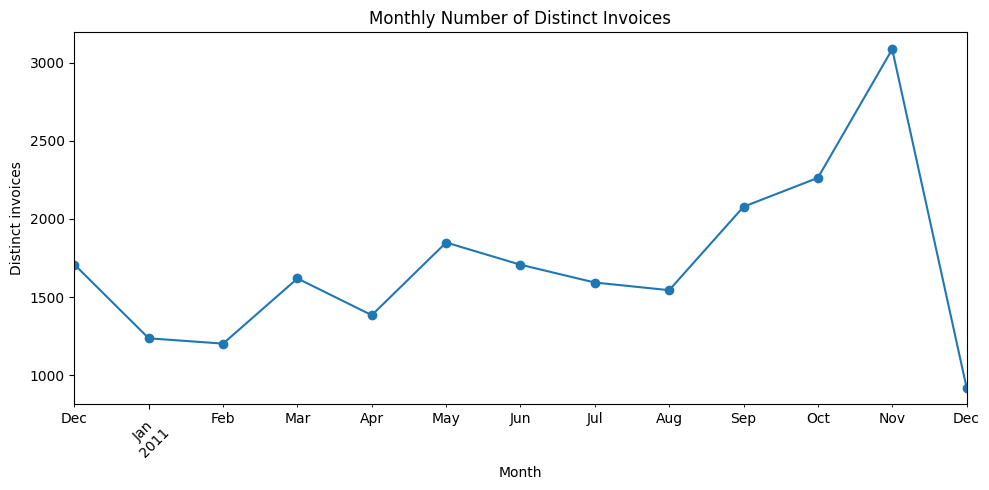

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert InvoiceDate to datetime objects
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

monthly_transactions = (
    df_clean.set_index("InvoiceDate")
    .resample("ME")["InvoiceNo"]
    .nunique()
)

print(monthly_transactions)

monthly_transactions.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Monthly Number of Distinct Invoices"
)

plt.xlabel("Month")
plt.ylabel("Distinct invoices")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
import pandas as pd

# Ensure InvoiceDate is in datetime format and calculate Revenue
df_sales["InvoiceDate"] = pd.to_datetime(df_sales["InvoiceDate"])
df_sales["Revenue"] = df_sales["Quantity"] * df_sales["UnitPrice"]

customer_summary = df_sales.groupby("CustomerID").agg(
    total_orders=("InvoiceNo", "nunique"),
    total_revenue=("Revenue", "sum"),
    first_purchase=("InvoiceDate", "min"),
    last_purchase=("InvoiceDate", "max")
)

customer_summary["days_between_first_and_last"] = (
    customer_summary["last_purchase"] -
    customer_summary["first_purchase"]
).dt.days

customer_summary["customer_type"] = (
    customer_summary["total_orders"]
    .apply(lambda x: "Repeat" if x > 1 else "One-time")
)

display(customer_summary.head(10))

print("\nCustomer type counts:")
print(customer_summary["customer_type"].value_counts())

print("\nAverage revenue per customer:")
print(round(customer_summary["total_revenue"].mean(), 2))

,total_orders,total_revenue,first_purchase,last_purchase,days_between_first_and_last,customer_type
CustomerID,,,,,,
12346.0,1,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00,0,One-time
12347.0,7,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00,365,Repeat
12348.0,4,1797.24,2010-12-16 19:09:00,2011-09-25 13:13:00,282,Repeat
12349.0,1,1757.55,2011-11-21 09:51:00,2011-11-21 09:51:00,0,One-time
12350.0,1,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00,0,One-time
12352.0,8,2506.04,2011-02-16 12:33:00,2011-11-03 14:37:00,260,Repeat
12353.0,1,89.00,2011-05-19 17:47:00,2011-05-19 17:47:00,0,One-time
12354.0,1,1079.40,2011-04-21 13:11:00,2011-04-21 13:11:00,0,One-time
12355.0,1,459.40,2011-05-09 13:49:00,2011-05-09 13:49:00,0,One-time



Customer type counts:
customer_type
Repeat      2845
One-time    1494
Name: count, dtype: int64

Average revenue per customer:
2048.22


,customers,average_orders,average_revenue
customer_type,,,
One-time,1494,1.00,410.97
Repeat,2845,5.99,2907.99


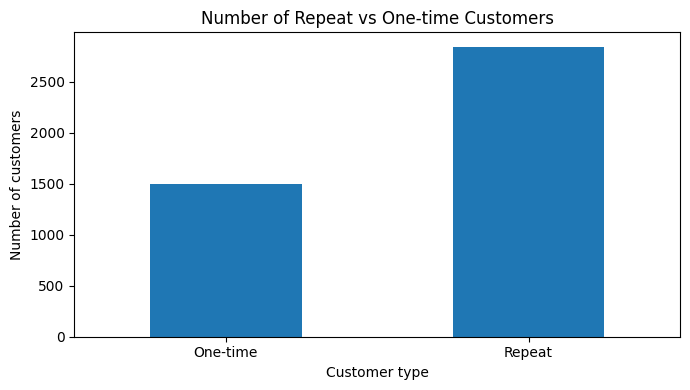

In [25]:
customer_comparison = customer_summary.groupby(
    "customer_type"
).agg(
    customers=("total_orders", "count"),
    average_orders=("total_orders", "mean"),
    average_revenue=("total_revenue", "mean")
).round(2)

display(customer_comparison)

customer_comparison["customers"].plot(
    kind="bar",
    figsize=(7, 4),
    title="Number of Repeat vs One-time Customers"
)

plt.xlabel("Customer type")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
analysis_end_date = df_clean["InvoiceDate"].max()

customer_summary["days_since_last_purchase"] = (
    analysis_end_date -
    customer_summary["last_purchase"]
).dt.days

customer_summary["needs_review"] = (
    customer_summary["days_since_last_purchase"] >= 90
)

print("Dataset end date:", analysis_end_date)
print(
    "Customers with 90+ days since last purchase:",
    int(customer_summary["needs_review"].sum())
)

display(
    customer_summary.sort_values(
        "days_since_last_purchase",
        ascending=False
    ).head(10)
)

Dataset end date: 2011-12-09 12:50:00
Customers with 90+ days since last purchase: 1449


,total_orders,total_revenue,first_purchase,last_purchase,days_between_first_and_last,customer_type,days_since_last_purchase,needs_review
CustomerID,,,,,,,,
18074.0,1,489.60,2010-12-01 09:53:00,2010-12-01 09:53:00,0,One-time,373,True
12791.0,1,192.60,2010-12-01 11:27:00,2010-12-01 11:27:00,0,One-time,373,True
14729.0,1,313.49,2010-12-01 12:43:00,2010-12-01 12:43:00,0,One-time,373,True
16583.0,1,233.45,2010-12-01 12:03:00,2010-12-01 12:03:00,0,One-time,373,True
13747.0,1,79.60,2010-12-01 10:37:00,2010-12-01 10:37:00,0,One-time,373,True
17968.0,1,265.10,2010-12-01 12:23:00,2010-12-01 12:23:00,0,One-time,373,True
17908.0,1,232.03,2010-12-01 11:45:00,2010-12-01 11:45:00,0,One-time,373,True
15363.0,1,326.00,2010-12-02 12:28:00,2010-12-02 12:28:00,0,One-time,372,True
17925.0,1,244.08,2010-12-02 10:10:00,2010-12-02 10:10:00,0,One-time,372,True


In [28]:
customer_summary.to_csv(
    "customer_retention_summary.csv"
)

monthly_transactions.to_csv(
    "monthly_invoice_counts.csv"
)

print("Analysis files created successfully!")

Analysis files created successfully!
